<a href="https://colab.research.google.com/github/ErrPeppe/OhnomiTools/blob/main/05_sensitivity_and_controls.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 5 — Controlli di Sensibilità, Robustezza Statistica ed Esportazione LaTeX

Questo notebook esegue una batteria sistematica di controlli di robustezza sui risultati ottenuti nelle Fasi 2–4, verificando che le firme evolutive, topologiche e trascrizionali osservate nei candidati *ohno-lncRNA* non dipendano da artefatti di annotazione, confondenti genomici o scelte di catalogo:

1. **Controllo 1 — Orientamento trascrizionale (`sense` vs `antisense`):** test dell'ipotesi di *read-through* passivo del gene host sulla co-espressione a coppie (Fase 4).
2. **Controllo 2 — Anti-pseudoreplicazione:** aggregazione a una singola osservazione per coppia di geni host (`pair_key`) e analisi del sottoinsieme `1:1` puro sulle Fasi 3 e 4.
3. **Controllo 3 — Purezza non codificante (`SmProt`):** replica della curva filostratigrafica $A \cap B$ (Fase 2) e della divergenza di espressione (Fase 4) escludendo i loci con evidenza di micropeptidi (`all` e `ms_only`).
4. **Controllo 4 — Sensibilità al catalogo WGD:** confronto sistematico tra `Ohnologs.com`, `Ohnologs.com` con controllo SSD decontaminato e il catalogo indipendente `MakinoSinghStrict` (Mottes et al., 2021; Agasso et al., 2025).
5. **Controllo 5 — Esportazione riproducibile verso LaTeX:** generazione automatica delle macro numeriche (`metrics.tex`) e delle tabelle `booktabs` (`tab_*.tex`) in `gold/latex_auto/`.

## 1. Setup Ambiente

In [1]:
!pip install -q --no-cache-dir --no-deps git+https://github.com/ErrPeppe/OhnomiTools.git

from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from ohnomitools import setup_colab
from ohnomitools.evolution import EvolutionAnalyzer
from ohnomitools.network import NetworkMotifAnalyzer
from ohnomitools.expression import MultiOmicsExpressionAnalyzer
from ohnomitools.reporting import (
    LatexExporter,
    format_ci,
    format_float,
    format_int,
    format_pct,
    format_pvalue,
)

PATHS = setup_colab(show_status=False)
ev = EvolutionAnalyzer(PATHS)
na = NetworkMotifAnalyzer(PATHS)
ea = MultiOmicsExpressionAnalyzer(PATHS)
df_mo = ea.build_gene_multiomics_table(force_rebuild=False)

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_cols(14)
print(f"Data root attiva: {PATHS.data_root}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Data root attiva: /content/rclone_drive


## Controllo 1 — Stratificazione `sense` vs `antisense` sulla co-espressione (Fase 4)

Se la minore divergenza di espressione osservata nelle coppie WGD rispetto alle coppie SSD antiche fosse un semplice riflesso di trascrizione *read-through* del gene codificante ospite, il segnale dovrebbe concentrarsi nei lncRNA orientati in `sense` rispetto all'host e attenuarsi o scomparire negli `antisense` (trascritti sul filamento opposto, con promotori indipendenti). Valutiamo la stratificazione sia a livello di singola coppia di lncRNA sia in combinazione con l'aggregazione mediana per coppia di geni host (`pair_key`).

In [2]:
ctrl1_pair = ea.analyze_sense_vs_antisense_divergence(
    df_mo,
    aggregate_by_host=None,
    save_outputs=True,
    output_tag="ctrl1_sense_vs_antisense",
)
ctrl1_host = ea.analyze_sense_vs_antisense_divergence(
    df_mo,
    aggregate_by_host="median",
    save_outputs=True,
    output_tag="ctrl1_sense_vs_antisense_host_median",
)

cols_show = ["Orientamento", "Via", "Metrica", "WGD_n", "WGD_media", "SSD_n", "SSD_media", "KS_p", "MW_p"]
print("=== CONTROLLO 1A — LIVELLO COPPIA lncRNA (SENSE vs ANTISENSE) ===")
print(ctrl1_pair["tests"].select(cols_show))

print("\n=== CONTROLLO 1B — AGGREGAZIONE MEDIANA PER PAIR_KEY HOST (SENSE vs ANTISENSE) ===")
print(ctrl1_host["tests"].select(cols_show))

=== CONTROLLO 1A — LIVELLO COPPIA lncRNA (SENSE vs ANTISENSE) ===
shape: (16, 9)
┌────────────┬──────┬────────────┬───────┬───────────┬────────┬───────────┬────────────┬───────────┐
│ Orientamen ┆ Via  ┆ Metrica    ┆ WGD_n ┆ WGD_media ┆ SSD_n  ┆ SSD_media ┆ KS_p       ┆ MW_p      │
│ to         ┆ ---  ┆ ---        ┆ ---   ┆ ---       ┆ ---    ┆ ---       ┆ ---        ┆ ---       │
│ ---        ┆ str  ┆ str        ┆ i64   ┆ f64       ┆ i64    ┆ f64       ┆ f64        ┆ f64       │
│ str        ┆      ┆            ┆       ┆           ┆        ┆           ┆            ┆           │
╞════════════╪══════╪════════════╪═══════╪═══════════╪════════╪═══════════╪════════════╪═══════════╡
│ sense      ┆ via1 ┆ cosine_dis ┆ 4922  ┆ 0.3163    ┆ 54093  ┆ 0.3205    ┆ 0.242893   ┆ 0.571302  │
│            ┆      ┆ tance      ┆       ┆           ┆        ┆           ┆            ┆           │
│ sense      ┆ via1 ┆ manhattan_ ┆ 6346  ┆ 0.2905    ┆ 74226  ┆ 0.3049    ┆ 1.0051e-10 ┆ 4.1529e-1 │
│         

## Controllo 2 — Anti-pseudoreplicazione: aggregazione per coppia host e sottoinsieme `1:1` puro (Fasi 3 e 4)

Quando un gene host ospita più geni lncRNA, il prodotto cartesiano genera più coppie di lncRNA per la stessa coppia di host (`pair_key`), introducendo potenziale dipendenza statistica tra osservazioni condivise. Per verificare la robustezza dei test di Fase 3 (layer miRNA) e Fase 4 (divergenza di espressione), ripetiamo i confronti WGD vs SSD antiche con:

* **Aggregazione per `pair_key` di host** (un solo valore mediano per coppia di geni codificanti, azzerando la pseudoreplicazione);
* **Sottoinsieme `1:1` puro** (`is_strict_1to1_host == True`: coppie in cui ciascun gene host contiene esattamente un solo gene lncRNA), includendo il modello nullo microcanonico di Maslov–Sneppen ($N_{\text{rand}} = 1{,}000$) sul layer miRNA.

In [3]:
# --- Fase 4: aggregazione per coppia host + subset 1:1 ---
ctrl2_p4_host_med = ea.analyze_pairwise_expression_divergence(
    df_mo, aggregate_by_host="median", save_outputs=True, output_tag="ctrl2_host_median"
)
ctrl2_p4_host_mean = ea.analyze_pairwise_expression_divergence(
    df_mo, aggregate_by_host="mean", save_outputs=True, output_tag="ctrl2_host_mean"
)
ctrl2_p4_1to1 = ea.analyze_pairwise_expression_divergence(
    df_mo, strict_1to1_only=True, save_outputs=True, output_tag="ctrl2_strict_1to1"
)

print("=== CONTROLLO 2 (FASE 4) — MEDIANA PER PAIR_KEY HOST ===")
print(ctrl2_p4_host_med["tests"].select(["Via", "Metrica", "WGD_n", "WGD_media", "SSD_n", "SSD_media", "MW_p"]))
print("\n=== CONTROLLO 2 (FASE 4) — SUBSET STRICT 1:1 ===")
print(ctrl2_p4_1to1["tests"].select(["Via", "Metrica", "WGD_n", "WGD_media", "SSD_n", "SSD_media", "MW_p"]))

# --- Fase 3 (Layer miRNA): aggregazione per host + modello nullo su subset 1:1 ---
net_mir = na.build_network("mirna")

# Le metriche osservate per coppia non dipendono da n_null: n_null=2 estrae velocemente pair_tables
mir_v1_obs = na.analyze_pair_motifs_and_null_models(net_mir, lane="via1", n_null=2, save_outputs=False)
mir_v2_obs = na.analyze_pair_motifs_and_null_models(net_mir, lane="via2", n_null=2, save_outputs=False)

ctrl2_p3_v1_host = na.compare_host_aggregated_pair_metrics(mir_v1_obs["pair_tables"], "mirna", "via1", agg="median")
ctrl2_p3_v2_host = na.compare_host_aggregated_pair_metrics(mir_v2_obs["pair_tables"], "mirna", "via2", agg="median")
ctrl2_p3_host = pl.concat([ctrl2_p3_v1_host, ctrl2_p3_v2_host], how="vertical")
ctrl2_p3_host.write_csv(PATHS.gold / "phase5_ctrl2_mirna_host_aggregated.csv")

# Modello nullo completo (n_null=1000) sul subset 1:1 puro (Via 1 e Via 2)
ctrl2_p3_v1_1to1 = na.analyze_pair_motifs_and_null_models(
    net_mir, lane="via1", n_null=1000, strict_1to1_only=True, save_outputs=True, output_tag="ctrl2"
)
ctrl2_p3_v2_1to1 = na.analyze_pair_motifs_and_null_models(
    net_mir, lane="via2", n_null=1000, strict_1to1_only=True, save_outputs=True, output_tag="ctrl2"
)

print("\n=== CONTROLLO 2 (FASE 3 miRNA) — MEDIANA PER PAIR_KEY HOST ===")
print(ctrl2_p3_host.select(["Via", "Metrica", "WGD_hosts_n", "WGD_media", "SSD_hosts_n", "SSD_media", "MW_p"]))
print("\n=== CONTROLLO 2 (FASE 3 miRNA) — SUBSET 1:1 PURO (Z-SCORE, n_null=1000) ===")
print(
    pl.concat([ctrl2_p3_v1_1to1["z_summary"], ctrl2_p3_v2_1to1["z_summary"]], how="vertical")
    .select(["Via", "Tipo", "Coppie_in_rete", "Metrica", "Osservato", "Null_Mean", "Z_score", "p_empirico"])
)

=== CONTROLLO 2 (FASE 4) — MEDIANA PER PAIR_KEY HOST ===
shape: (8, 7)
┌──────┬─────────────────┬───────┬───────────┬───────┬───────────┬───────────┐
│ Via  ┆ Metrica         ┆ WGD_n ┆ WGD_media ┆ SSD_n ┆ SSD_media ┆ MW_p      │
│ ---  ┆ ---             ┆ ---   ┆ ---       ┆ ---   ┆ ---       ┆ ---       │
│ str  ┆ str             ┆ i64   ┆ f64       ┆ i64   ┆ f64       ┆ f64       │
╞══════╪═════════════════╪═══════╪═══════════╪═══════╪═══════════╪═══════════╡
│ via1 ┆ cosine_distance ┆ 1912  ┆ 0.3277    ┆ 30116 ┆ 0.3525    ┆ 0.000002  │
│ via1 ┆ manhattan_norm  ┆ 2130  ┆ 0.2701    ┆ 35384 ┆ 0.285     ┆ 2.3709e-9 │
│ via1 ┆ expr_asymmetry  ┆ 2130  ┆ 0.4137    ┆ 35384 ┆ 0.4509    ┆ 0.000002  │
│ via1 ┆ exact_ctx_match ┆ 2130  ┆ 0.4907    ┆ 35384 ┆ 0.4703    ┆ 7.9843e-8 │
│ via2 ┆ cosine_distance ┆ 255   ┆ 0.3856    ┆ 2600  ┆ 0.387     ┆ 0.539345  │
│ via2 ┆ manhattan_norm  ┆ 361   ┆ 0.2413    ┆ 4075  ┆ 0.2574    ┆ 0.080449  │
│ via2 ┆ expr_asymmetry  ┆ 361   ┆ 0.4681    ┆ 4075  ┆ 0.498


=== CONTROLLO 2 (FASE 3 miRNA) — MEDIANA PER PAIR_KEY HOST ===
shape: (14, 7)
┌──────┬────────────────────┬─────────────┬───────────┬─────────────┬───────────┬──────────┐
│ Via  ┆ Metrica            ┆ WGD_hosts_n ┆ WGD_media ┆ SSD_hosts_n ┆ SSD_media ┆ MW_p     │
│ ---  ┆ ---                ┆ ---         ┆ ---       ┆ ---         ┆ ---       ┆ ---      │
│ str  ┆ str                ┆ i64         ┆ f64       ┆ i64         ┆ f64       ┆ f64      │
╞══════╪════════════════════╪═════════════╪═══════════╪═════════════╪═══════════╪══════════╡
│ via1 ┆ sorensen_dice      ┆ 766         ┆ 0.04      ┆ 9998        ┆ 0.04388   ┆ 0.604699 │
│ via1 ┆ jaccard            ┆ 766         ┆ 0.03405   ┆ 9998        ┆ 0.03763   ┆ 0.603903 │
│ via1 ┆ v_motifs           ┆ 766         ┆ 0.0594    ┆ 9998        ┆ 0.06216   ┆ 0.626217 │
│ via1 ┆ generic_k22_bifans ┆ 766         ┆ 0.00196   ┆ 9998        ┆ 0.00085   ┆ 0.153439 │
│ via1 ┆ norm_delta_k       ┆ 766         ┆ 0.20529   ┆ 9998        ┆ 0.19499   ┆ 0.

## Controllo 3 — Purezza non codificante (`has_sprotein == False`, SmProt)

L'annotazione `SmProt` in LncBook v2.0 (Li et al., 2023) evidenzia che fino al ~30% dei trascritti antichi al nodo `17. Euteleostomi` contiene piccole ORF con potenziale codificante criptico (evidenza Ribo-seq o spettrometria di massa). Per escludere che l'arricchimento intragenico (Fase 2) o la co-espressione delle coppie WGD (Fase 4) siano guidati da micropeptidi erroneamente classificati come lncRNA, replichiamo entrambe le analisi rimuovendo:

* tutti i geni annotati in `SmProt` (`exclude_sprotein="all"`);
* i soli geni con evidenza sperimentale di spettrometria di massa (`exclude_sprotein="ms_only"`).

In [4]:
# --- Fase 2: controllo lunghezza + curva A ∩ B senza SmProt ---
ctrl3_p2_all = ev.run_sensitivity_phase2(
    label="No_SmProt_all",
    exclude_sprotein="all",
    output_tag="ctrl3_no_sprotein_all",
)
ctrl3_p2_ms = ev.run_sensitivity_phase2(
    label="No_SmProt_ms_only",
    exclude_sprotein="ms_only",
    output_tag="ctrl3_no_sprotein_ms",
)

print("=== CONTROLLO 3 (FASE 2) — NO SMPROT (ALL) ===")
print(ctrl3_p2_all["ab_curve"].select(["Soglia_A_cap_B", "WGD_host_pos", "SSD_host_pos", "OR_crude", "OR_adj_length", "Logistic_p"]))

print("\n=== CONTROLLO 3 (FASE 2) — NO SMPROT (MS ONLY) ===")
print(ctrl3_p2_ms["ab_curve"].select(["Soglia_A_cap_B", "WGD_host_pos", "SSD_host_pos", "OR_crude", "OR_adj_length", "Logistic_p"]))

# --- Fase 4: divergenza di espressione senza SmProt ---
ctrl3_p4_all = ea.analyze_pairwise_expression_divergence(
    df_mo, exclude_sprotein="all", save_outputs=True, output_tag="ctrl3_no_sprotein_all"
)
ctrl3_p4_ms = ea.analyze_pairwise_expression_divergence(
    df_mo, exclude_sprotein="ms_only", save_outputs=True, output_tag="ctrl3_no_sprotein_ms"
)

print("\n=== CONTROLLO 3 (FASE 4) — CO-ESPRESSIONE NO SMPROT (ALL) ===")
print(ctrl3_p4_all["tests"].select(["Via", "Metrica", "WGD_n", "WGD_media", "SSD_n", "SSD_media", "MW_p"]))

print("\n=== CONTROLLO 3 (FASE 4) — CO-ESPRESSIONE NO SMPROT (MS ONLY) ===")
print(ctrl3_p4_ms["tests"].select(["Via", "Metrica", "WGD_n", "WGD_media", "SSD_n", "SSD_media", "MW_p"]))

=== CONTROLLO 3 (FASE 2) — NO SMPROT (ALL) ===
shape: (6, 6)
┌────────────────────────────┬──────────────┬──────────────┬──────────┬───────────────┬────────────┐
│ Soglia_A_cap_B             ┆ WGD_host_pos ┆ SSD_host_pos ┆ OR_crude ┆ OR_adj_length ┆ Logistic_p │
│ ---                        ┆ ---          ┆ ---          ┆ ---      ┆ ---           ┆ ---        │
│ str                        ┆ i64          ┆ i64          ┆ f64      ┆ f64           ┆ f64        │
╞════════════════════════════╪══════════════╪══════════════╪══════════╪═══════════════╪════════════╡
│ 1. Ramo A puro (Tutte le   ┆ 2000         ┆ 33255        ┆ 2.3088   ┆ 1.2199        ┆ 4.2031e-7  │
│ età)                       ┆              ┆              ┆          ┆               ┆            │
│ 2. A ∩ B (Entrambi >= 14.  ┆ 367          ┆ 4475         ┆ 2.4268   ┆ 1.1674        ┆ 0.012655   │
│ Mamm…                      ┆              ┆              ┆          ┆               ┆            │
│ 3. A ∩ B (Entrambi >= 15.  ┆

## Controllo 4 — Sensibilità al catalogo WGD (`Ohnologs.com` vs `MakinoSinghStrict` e SSD decontaminato)

L'analisi primaria utilizza le coppie WGD umane macro-sinteniche di `Ohnologs.com` (`4.221` coppie). Per verificare la dipendenza dei risultati dalla definizione operativa di ohnologo — e quantificare l'effetto delle `5.221` coppie presenti nel catalogo `MakinoSinghStrict` (Mottes et al., 2021; Agasso et al., 2025) che ricadono nell'insieme grezzo dei paraloghi Ensembl — confrontiamo tre configurazioni della Fase 2 (controllo lunghezza + curva $A \cap B$):

1. **Baseline `Ohnologs.com`** (catalogo primario contro SSD Ensembl antiche $>$ *Sarcopterygii*);
2. **`Ohnologs.com` + SSD decontaminato** (rimuovendo dal controllo SSD l'intera intersezione con `MakinoSinghStrict`);
3. **`MakinoSinghStrict` + SSD decontaminato** (catalogo WGD alternativo completo mappato su geni Ensembl `protein_coding` canonici).

In [5]:
ms_bundle = ev.load_makino_singh_strict_hosts(download_if_missing=True)
print("=== STATISTICHE OVERLAP MAKINO-SINGH STRICT ===")
for k, v in ms_bundle["stats"].items():
    print(f"  {k}: {v:,}")

ctrl4_base = ev.run_sensitivity_phase2(
    label="Ohnologs.com (baseline)",
    output_tag=None,
)
ctrl4_ohno_clean = ev.run_sensitivity_phase2(
    label="Ohnologs.com + SSD decontaminato",
    df_ssd_hosts=ms_bundle["ssd_decontaminated"],
    output_tag="ctrl4_ohnologs_ssd_clean",
)
ctrl4_ms_clean = ev.run_sensitivity_phase2(
    label="MakinoSinghStrict + SSD decontaminato",
    df_wgd_hosts=ms_bundle["wgd_makino"],
    df_ssd_hosts=ms_bundle["ssd_decontaminated"],
    output_tag="ctrl4_makino_ssd_clean",
)

ctrl4_rows = []
for res in (ctrl4_base, ctrl4_ohno_clean, ctrl4_ms_clean):
    m = res["length_control"]["metrics"]
    row_v2 = res["ab_curve"].filter(pl.col("Soglia_A_cap_B").str.contains("15. Amniota"))
    ctrl4_rows.append({
        "Catalogo": res["label"],
        "WGD_hosts": res["n_wgd_hosts"],
        "SSD_ancient_hosts": res["n_ssd_hosts"],
        "OR_MH_Via1": m["OR_MantelHaenszel_stratified"],
        "OR_MH_CI95_low": m["OR_MH_CI95_low"],
        "OR_MH_CI95_high": m["OR_MH_CI95_high"],
        "OR_adj_Via1": m["OR_adj_length"],
        "OR_adj_Via1_lo": m["OR_adj_CI95_low"],
        "OR_adj_Via1_hi": m["OR_adj_CI95_high"],
        "p_Via1": m["Logistic_p_value"],
        "WGD_pos_Via2": int(row_v2["WGD_host_pos"][0]),
        "OR_adj_Via2": float(row_v2["OR_adj_length"][0]),
        "OR_adj_Via2_lo": float(row_v2["OR_adj_CI95_low"][0]),
        "OR_adj_Via2_hi": float(row_v2["OR_adj_CI95_high"][0]),
        "p_Via2": float(row_v2["Logistic_p"][0]),
    })

df_ctrl4_summary = pl.DataFrame(ctrl4_rows)
df_ctrl4_summary.write_csv(PATHS.gold / "phase5_ctrl4_wgd_catalogs_comparison.csv")
print("\n=== CONTROLLO 4 — CONFRONTO CATALOGHI WGD (VIA 1 & VIA 2 >=15 AMNIOTA) ===")
print(df_ctrl4_summary.select(["Catalogo", "WGD_hosts", "OR_MH_Via1", "OR_adj_Via1", "p_Via1", "WGD_pos_Via2", "OR_adj_Via2", "p_Via2"]))

=== STATISTICHE OVERLAP MAKINO-SINGH STRICT ===
  makino_raw_pairs: 8,070
  makino_mapped_ensg_pairs: 8,022
  overlap_with_ohnologs_com_ensg: 2,791
  ssd_raw_pairs: 127,578
  ssd_removed_makino_overlap: 5,221
  ssd_decontaminated_pairs: 122,357
  ssd_decontaminated_ancient_pairs: 113,325

=== CONTROLLO 4 — CONFRONTO CATALOGHI WGD (VIA 1 & VIA 2 >=15 AMNIOTA) ===
shape: (3, 8)
┌────────────┬───────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┐
│ Catalogo   ┆ WGD_hosts ┆ OR_MH_Via1 ┆ OR_adj_Via ┆ p_Via1    ┆ WGD_pos_V ┆ OR_adj_Vi ┆ p_Via2    │
│ ---        ┆ ---       ┆ ---        ┆ 1          ┆ ---       ┆ ia2       ┆ a2        ┆ ---       │
│ str        ┆ i64       ┆ f64        ┆ ---        ┆ f64       ┆ ---       ┆ ---       ┆ f64       │
│            ┆           ┆            ┆ f64        ┆           ┆ i64       ┆ f64       ┆           │
╞════════════╪═══════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ Ohnologs.c ┆ 

## Figura riassuntiva controlli 1-4

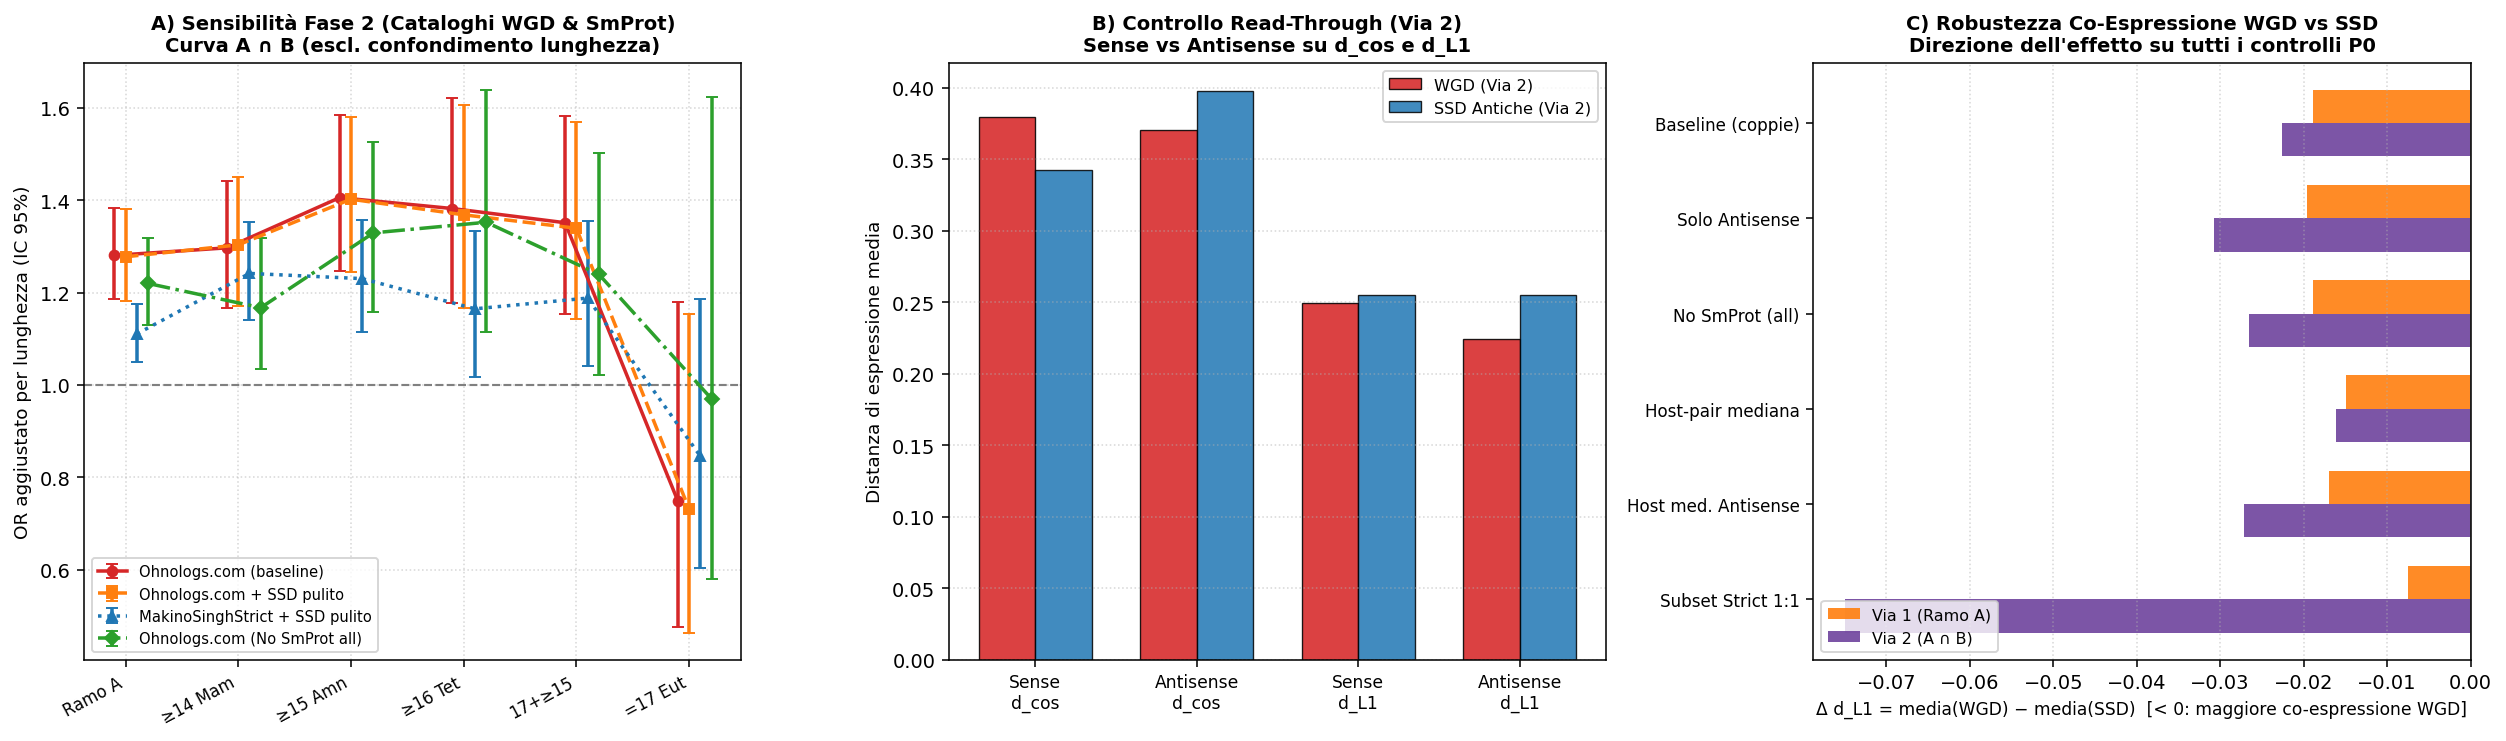

Salvata figura riassuntiva in gold/phase5_sensitivity_controls_summary.{png,pdf}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18.0, 5.4), dpi=140)
fig.patch.set_facecolor("white")

# --- Pannello A: Controllo 4 (OR aggiustato lungo la curva A ∩ B nei 3 cataloghi) ---
ax = axes[0]
short_x = ["Ramo A", "≥14 Mam", "≥15 Amn", "≥16 Tet", "17+≥15", "=17 Eut"]
x_idx = np.arange(len(short_x))
catalog_specs = [
    (ctrl4_base["ab_curve"], "Ohnologs.com (baseline)", "#D62728", "o-", -0.10),
    (ctrl4_ohno_clean["ab_curve"], "Ohnologs.com + SSD pulito", "#FF7F0E", "s--", 0.0),
    (ctrl4_ms_clean["ab_curve"], "MakinoSinghStrict + SSD pulito", "#1F77B4", "^:", 0.10),
    (ctrl3_p2_all["ab_curve"], "Ohnologs.com (No SmProt all)", "#2CA02C", "D-.", 0.20),
]
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1.1)
for df_c, lbl, col, fmt, shift in catalog_specs:
    y = df_c["OR_adj_length"].to_numpy()
    lo = np.clip(y - df_c["OR_adj_CI95_low"].to_numpy(), 0, None)
    hi = np.clip(df_c["OR_adj_CI95_high"].to_numpy() - y, 0, None)
    ax.errorbar(x_idx + shift, y, yerr=[lo, hi], fmt=fmt, color=col, capsize=3, linewidth=1.8, markersize=5, label=lbl)
ax.set_xticks(x_idx)
ax.set_xticklabels(short_x, rotation=28, ha="right", fontsize=8.5)
ax.set_ylabel("OR aggiustato per lunghezza (IC 95%)", fontsize=9.5)
ax.set_title("A) Sensibilità Fase 2 (Cataloghi WGD & SmProt)\nCurva A ∩ B (escl. confondimento lunghezza)", fontsize=10, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(fontsize=7.6, loc="lower left")

# --- Pannello B: Controllo 1 (Sense vs Antisense su d_L1 e d_cos in Via 2) ---
ax = axes[1]
t_sa = ctrl1_pair["tests"].filter(pl.col("Via") == "via2")
labels_b = ["Sense\nd_cos", "Antisense\nd_cos", "Sense\nd_L1", "Antisense\nd_L1"]
w_vals, s_vals = [], []
for met in ("cosine_distance", "manhattan_norm"):
    for ori in ("sense", "antisense"):
        r = t_sa.filter((pl.col("Metrica") == met) & (pl.col("Orientamento") == ori))
        w_vals.append(float(r["WGD_media"][0]) if len(r) else 0.0)
        s_vals.append(float(r["SSD_media"][0]) if len(r) else 0.0)
xb = np.arange(len(labels_b))
w = 0.35
ax.bar(xb - w / 2, w_vals, width=w, color="#D62728", alpha=0.88, edgecolor="black", linewidth=0.7, label="WGD (Via 2)")
ax.bar(xb + w / 2, s_vals, width=w, color="#1F77B4", alpha=0.85, edgecolor="black", linewidth=0.7, label="SSD Antiche (Via 2)")
ax.set_xticks(xb)
ax.set_xticklabels(labels_b, fontsize=8.8)
ax.set_ylim(bottom=0.0)
ax.set_ylabel("Distanza di espressione media", fontsize=9.5)
ax.set_title("B) Controllo Read-Through (Via 2)\nSense vs Antisense su d_cos e d_L1", fontsize=10, fontweight="bold")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)
ax.legend(fontsize=8.3, loc="upper right")

# --- Pannello C: Controlli 2 & 3 sulla differenza media Δd_L1 (WGD − SSD) ---
ax = axes[2]
p4_base_tests = pl.read_csv(PATHS.gold / "phase4_pairwise_expression_tests.csv")
ctrl_specs_c = [
    ("Baseline (coppie)", p4_base_tests),
    ("Solo Antisense", ctrl1_pair["tests"].filter(pl.col("Orientamento") == "antisense")),
    ("No SmProt (all)", ctrl3_p4_all["tests"]),
    ("Host-pair mediana", ctrl2_p4_host_med["tests"]),
    ("Host med. Antisense", ctrl1_host["tests"].filter(pl.col("Orientamento") == "antisense")),
    ("Subset Strict 1:1", ctrl2_p4_1to1["tests"]),
]
yc = np.arange(len(ctrl_specs_c))
d_v1, d_v2 = [], []
for _, dft in ctrl_specs_c:
    r1 = dft.filter((pl.col("Via") == "via1") & (pl.col("Metrica") == "manhattan_norm"))
    r2 = dft.filter((pl.col("Via") == "via2") & (pl.col("Metrica") == "manhattan_norm"))
    d_v1.append(float(r1["WGD_media"][0] - r1["SSD_media"][0]) if len(r1) else 0.0)
    d_v2.append(float(r2["WGD_media"][0] - r2["SSD_media"][0]) if len(r2) else 0.0)
h = 0.35
ax.axvline(0.0, color="gray", linestyle="-", linewidth=0.9)
ax.barh(yc - h / 2, d_v1, height=h, color="#FF7F0E", alpha=0.9, label="Via 1 (Ramo A)")
ax.barh(yc + h / 2, d_v2, height=h, color="#6A3D9A", alpha=0.88, label="Via 2 (A ∩ B)")
ax.set_yticks(yc)
ax.set_yticklabels([c[0] for c in ctrl_specs_c], fontsize=8.6)
ax.invert_yaxis()
ax.set_xlabel("Δ d_L1 = media(WGD) − media(SSD)  [< 0: maggiore co-espressione WGD]", fontsize=8.8)
ax.set_title("C) Robustezza Co-Espressione WGD vs SSD\nDirezione dell'effetto su tutti i controlli P0", fontsize=10, fontweight="bold")
ax.grid(True, axis="x", linestyle=":", alpha=0.5)
ax.legend(fontsize=8.2, loc="upper left")

plt.tight_layout()
fig.savefig(PATHS.gold / "phase5_sensitivity_controls_summary.png", dpi=300, bbox_inches="tight")
fig.savefig(PATHS.gold / "phase5_sensitivity_controls_summary.pdf", bbox_inches="tight")
plt.show()
print("Salvata figura riassuntiva in gold/phase5_sensitivity_controls_summary.{png,pdf}")

## Controllo 5 — Esportazione automatica verso LaTeX (`gold/latex_auto/`)

Consolidiamo le metriche canoniche aggiornate (Fasi 1–4 con $N_{\text{rand}} = 1{,}000$ e disgiunzione WGD/SSD) e le tabelle di sensibilità dei Controlli 1–4 in `Data/gold/latex_auto/metrics.tex` e nei frammenti `booktabs` `tab_*.tex`, tramite `LatexExporter`.

In [7]:
exp = LatexExporter(PATHS)

# Lettura dei file canonici aggiornati in Silver / Gold
df_lnc_genes = pl.read_parquet(PATHS.silver_lncrna_genes)
df_via3 = pl.read_parquet(PATHS.silver_lane3_euteleostomi)
df_wgd_genes = pl.read_parquet(PATHS.silver_wgd_genes)
df_wgd_pairs = pl.read_parquet(PATHS.silver_wgd_pairs)
df_ssd_pairs = ev._standardize_ssd_clade_column(pl.read_parquet(PATHS.silver_ssd_pairs))
df_l1_wgd = pl.read_parquet(PATHS.silver_lane1_wgd_pairs)
df_l2_wgd = pl.read_parquet(PATHS.silver_lane2_wgd_pairs)

df_p2_len = pl.read_csv(PATHS.gold / "phase2_length_control_summary.csv")
df_p2_ab = pl.read_csv(PATHS.gold / "phase2_ab_sensitivity_curve.csv")
df_p3_mir_v1 = pl.read_csv(PATHS.gold / "phase3_mirna_via1_null_zscores.csv")
df_p3_mir_v2 = pl.read_csv(PATHS.gold / "phase3_mirna_via2_null_zscores.csv")
df_p3_rbp_delta = pl.read_csv(PATHS.gold / "phase3_rbp_via3_ppi_delta.csv")
df_p4_pair_tests = pl.read_csv(PATHS.gold / "phase4_pairwise_expression_tests.csv")

m_len = df_p2_len.row(0, named=True)
r_ab_v2 = df_p2_ab.filter(pl.col("Soglia_A_cap_B").str.contains("15. Amniota")).row(0, named=True)

def _pick_row(df: pl.DataFrame, cond: pl.Expr) -> dict:
    return df.filter(cond).row(0, named=True)

mir_v2_wgd_v = _pick_row(df_p3_mir_v2, (pl.col("Tipo") == "WGD") & (pl.col("Metrica") == "V-Motifs (totale)"))
mir_v2_ssd_v = _pick_row(df_p3_mir_v2, (pl.col("Tipo") == "SSD") & (pl.col("Metrica") == "V-Motifs (totale)"))
rbp_d_c_wgd = _pick_row(df_p3_rbp_delta, (pl.col("Tipo_Motivo") == "ppi_complex_delta") & (pl.col("Coorte_Via3") == "Eut_intragenic_WGD"))
rbp_d_d_wgd = _pick_row(df_p3_rbp_delta, (pl.col("Tipo_Motivo") == "ppi_dup_delta") & (pl.col("Coorte_Via3") == "Eut_intragenic_WGD"))
rbp_d_c_linc = _pick_row(df_p3_rbp_delta, (pl.col("Tipo_Motivo") == "ppi_complex_delta") & (pl.col("Coorte_Via3") == "Eut_intergenic_lincRNA"))
rbp_d_d_linc = _pick_row(df_p3_rbp_delta, (pl.col("Tipo_Motivo") == "ppi_dup_delta") & (pl.col("Coorte_Via3") == "Eut_intergenic_lincRNA"))
rbp_d_c_homo = _pick_row(df_p3_rbp_delta, (pl.col("Tipo_Motivo") == "ppi_complex_delta") & (pl.col("Coorte_Via3") == "Control_1_Homo"))

p4_v2_cos = _pick_row(df_p4_pair_tests, (pl.col("Via") == "via2") & (pl.col("Metrica") == "cosine_distance"))
p4_v2_man = _pick_row(df_p4_pair_tests, (pl.col("Via") == "via2") & (pl.col("Metrica") == "manhattan_norm"))
c1_v2_cos = _pick_row(ctrl1_pair["tests"], (pl.col("Orientamento") == "antisense") & (pl.col("Via") == "via2") & (pl.col("Metrica") == "cosine_distance"))
c1_v2_man = _pick_row(ctrl1_pair["tests"], (pl.col("Orientamento") == "antisense") & (pl.col("Via") == "via2") & (pl.col("Metrica") == "manhattan_norm"))
c3_v2_cos = _pick_row(ctrl3_p4_all["tests"], (pl.col("Via") == "via2") & (pl.col("Metrica") == "cosine_distance"))
c3_v2_man = _pick_row(ctrl3_p4_all["tests"], (pl.col("Via") == "via2") & (pl.col("Metrica") == "manhattan_norm"))
c3_ab_v2 = _pick_row(ctrl3_p2_all["ab_curve"], pl.col("Soglia_A_cap_B").str.contains("15. Amniota"))

c4_ohno_cl = _pick_row(df_ctrl4_summary, pl.col("Catalogo").str.contains("SSD decontaminato") & pl.col("Catalogo").str.contains("Ohnologs"))
c4_ms_cl = _pick_row(df_ctrl4_summary, pl.col("Catalogo").str.contains("MakinoSinghStrict"))

# 1. Aggiornamento macro numeriche (solo lettere [A-Za-z])
metrics = {
    "NLncBookGenes": format_int(df_lnc_genes["gene_id"].n_unique()),
    "NEuteleostomiGenes": format_int(len(df_via3)),
    "NEutWgdHost": format_int(df_via3.filter(pl.col("genomic_context") == "intragenic_WGD_host").height),
    "NEutOtherHost": format_int(df_via3.filter(pl.col("genomic_context") == "intragenic_other_host").height),
    "NEutIntergenic": format_int(df_via3.filter(pl.col("genomic_context") == "intergenic_lincRNA").height),
    "NWgdGenes": format_int(df_wgd_genes["gene_id"].n_unique()),
    "NWgdPairs": format_int(df_wgd_pairs["pair_key"].n_unique()),
    "NSsdPurePairs": format_int(df_ssd_pairs["pair_key"].n_unique()),
    "NSsdAncientPairs": format_int(df_ssd_pairs.filter(pl.col("is_ancient_ssd") == True)["pair_key"].n_unique()),
    "NWgdPosViaOne": format_int(df_l1_wgd["pair_key"].n_unique()),
    "NWgdLncPairsViaOne": format_int(df_l1_wgd["lncrna_pair_key"].n_unique()),
    "NWgdStrictOneToOne": format_int(df_l1_wgd.filter(pl.col("is_strict_1to1_host") == True)["lncrna_pair_key"].n_unique()),
    "ORCrudeViaOne": format_float(m_len["OR_crude_Fisher"], 2),
    "ORMHViaOne": format_float(m_len["OR_MantelHaenszel_stratified"], 2),
    "ORMHCIViaOne": format_ci(m_len["OR_MantelHaenszel_stratified"], m_len["OR_MH_CI95_low"], m_len["OR_MH_CI95_high"], 2),
    "MHChiSqViaOne": format_float(m_len["MH_chi2"], 2),
    "PValMHViaOne": format_pvalue(m_len["MH_p_value"]),
    "ORAdjViaOne": format_float(m_len["OR_adj_length"], 2),
    "ORAdjCIViaOne": format_ci(m_len["OR_adj_length"], m_len["OR_adj_CI95_low"], m_len["OR_adj_CI95_high"], 2),
    "PValAdjViaOne": format_pvalue(m_len["Logistic_p_value"]),
    "NWgdPosViaTwo": format_int(r_ab_v2["WGD_host_pos"]),
    "NWgdLncPairsViaTwo": format_int(df_l2_wgd["lncrna_pair_key"].n_unique()),
    "ORAdjViaTwo": format_float(r_ab_v2["OR_adj_length"], 2),
    "ORAdjCIViaTwo": format_ci(r_ab_v2["OR_adj_length"], r_ab_v2["OR_adj_CI95_low"], r_ab_v2["OR_adj_CI95_high"], 2),
    "PValAdjViaTwo": format_pvalue(r_ab_v2["Logistic_p"]),
    "NMakinoRawPairs": format_int(ms_bundle["stats"]["makino_raw_pairs"]),
    "NMakinoMappedPairs": format_int(ms_bundle["stats"]["makino_mapped_ensg_pairs"]),
    "NMakinoOverlapOhno": format_int(ms_bundle["stats"]["overlap_with_ohnologs_com_ensg"]),
    "NSsdRemovedMakino": format_int(ms_bundle["stats"]["ssd_removed_makino_overlap"]),
    "ORAdjOhnoCleanViaOne": format_float(c4_ohno_cl["OR_adj_Via1"], 2),
    "ORAdjOhnoCleanViaTwo": format_float(c4_ohno_cl["OR_adj_Via2"], 2),
    "ORAdjMakinoViaOne": format_float(c4_ms_cl["OR_adj_Via1"], 2),
    "ORAdjMakinoViaTwo": format_float(c4_ms_cl["OR_adj_Via2"], 2),
    "ORAdjNoSmProtViaOne": format_float(ctrl3_p2_all["length_control"]["metrics"]["OR_adj_length"], 2),
    "ORAdjNoSmProtViaTwo": format_float(c3_ab_v2["OR_adj_length"], 2),
    "ZMirnaViaTwoWgd": format_float(mir_v2_wgd_v["Z_score"], 2),
    "PMirnaViaTwoWgd": format_pvalue(mir_v2_wgd_v["p_empirico"]),
    "ZMirnaViaTwoSsd": format_float(mir_v2_ssd_v["Z_score"], 2),
    "PMirnaViaTwoSsd": format_pvalue(mir_v2_ssd_v["p_empirico"]),
    "ZRbpPpiComplexWgd": format_float(rbp_d_c_wgd["Z_score"], 2),
    "PRbpPpiComplexWgd": format_pvalue(rbp_d_c_wgd["p_empirico"]),
    "ZRbpPpiDupWgd": format_float(rbp_d_d_wgd["Z_score"], 2),
    "PRbpPpiDupWgd": format_pvalue(rbp_d_d_wgd["p_empirico"]),
    "ZRbpPpiComplexLinc": format_float(rbp_d_c_linc["Z_score"], 2),
    "ZRbpPpiDupLinc": format_float(rbp_d_d_linc["Z_score"], 2),
    "ZRbpPpiComplexHomo": format_float(rbp_d_c_homo["Z_score"], 2),
    "PValCosDistViaTwo": format_pvalue(p4_v2_cos["MW_p"]),
    "PValManhattanViaTwo": format_pvalue(p4_v2_man["MW_p"]),
    "PValCosDistAntisenseViaTwo": format_pvalue(c1_v2_cos["MW_p"]),
    "PValManhattanAntisenseViaTwo": format_pvalue(c1_v2_man["MW_p"]),
    "PValCosDistNoSmProtViaTwo": format_pvalue(c3_v2_cos["MW_p"]),
    "PValManhattanNoSmProtViaTwo": format_pvalue(c3_v2_man["MW_p"]),
}
exp.update_metrics(metrics, source_tag="nb05_sensitivity_and_controls")

# 2. Esportazione tabelle LaTeX booktabs
# Tabella A: Curva A ∩ B canonica (Fase 2)
tab_ab = pl.DataFrame([
    {
        "Threshold": r["Soglia_A_cap_B"],
        "WGD_pos": int(r["WGD_host_pos"]),
        "SSD_pos": int(r["SSD_host_pos"]),
        "OR_crude": f"${format_float(r['OR_crude'], 2)}$",
        "OR_adj_CI": f"${format_ci(r['OR_adj_length'], r['OR_adj_CI95_low'], r['OR_adj_CI95_high'], 2)}$",
        "p_logit": f"${format_pvalue(r['Logistic_p'])}$",
    }
    for r in df_p2_ab.iter_rows(named=True)
])
exp.save_booktabs_table(
    tab_ab, "tab_phase2_ab_curve.tex",
    col_align="lrrrrr",
    headers=["Phylostratigraphic Threshold", "WGD Pos.", "SSD Pos.", r"$\OR_{\text{crude}}$", r"$\ORadj$ (95\% CI)", r"$p_{\text{logit}}$"],
    raw_columns={"OR_crude", "OR_adj_CI", "p_logit"},
    fit_width=True,
)

# Tabella B: Z-score Maslov-Sneppen Layer miRNA (Via 1 & Via 2, N_rand = 1,000)
df_mir_both = pl.concat([df_p3_mir_v1, df_p3_mir_v2], how="vertical")
tab_mir = pl.DataFrame([
    {
        "Lane": "Lane 1" if r["Via"] == "via1" else "Lane 2",
        "Type": r["Tipo"],
        "Pairs": int(r["Coppie_in_rete"]),
        "Metric": r["Metrica"],
        "Obs": f"${format_float(r['Osservato'], 4 if 'Dice' in r['Metrica'] else 1)}$",
        "Null": f"${format_float(r['Null_Mean'], 4 if 'Dice' in r['Metrica'] else 1)} \\pm {format_float(r['Null_Std'], 4 if 'Dice' in r['Metrica'] else 1)}$",
        "Z": f"${format_float(r['Z_score'], 2)}$",
        "p": f"${format_pvalue(r['p_empirico'])}$",
    }
    for r in df_mir_both.iter_rows(named=True)
])
exp.save_booktabs_table(
    tab_mir, "tab_phase3_mirna_null.tex",
    col_align="llrlrrrr",
    headers=["Lane", "Type", "Pairs", "Metric", "Observed", r"Null ($\mu \pm \sigma$)", r"$Z$", r"$p_{\text{emp}}$"],
    raw_columns={"Obs", "Null", "Z", "p"},
    fit_width=True,
)

# Tabella C: Via 3 RBP PPI-Delta (Complex vs Dup, N_rand = 1,000)
tab_delta = pl.DataFrame([
    {
        "Motif": "PPI-Complex Delta" if r["Tipo_Motivo"] == "ppi_complex_delta" else "PPI-Dup Delta",
        "Cohort": r["Coorte_Via3"],
        "N": int(r["N_in_rete"]),
        "Obs": int(r["Totale_osservato"]),
        "Null": f"${format_float(r['Null_Mean'], 2)} \\pm {format_float(r['Null_Std'], 2)}$",
        "Z": f"${format_float(r['Z_score'], 2)}$",
        "p": f"${format_pvalue(r['p_empirico'])}$",
    }
    for r in df_p3_rbp_delta.iter_rows(named=True)
])
exp.save_booktabs_table(
    tab_delta, "tab_phase3_rbp_via3_delta.tex",
    col_align="llrrrrr",
    headers=["Motif Type", "Lane 3 Cohort", r"$N$", "Observed", r"Null ($\mu \pm \sigma$)", r"$Z$", r"$p_{\text{emp}}$"],
    raw_columns={"Null", "Z", "p"},
    fit_width=True,
)

# Tabella D: Controllo 1 (Sense vs Antisense)
tab_c1 = pl.DataFrame([
    {
        "Strand": r["Orientamento"],
        "Lane": "Lane 1" if r["Via"] == "via1" else "Lane 2",
        "Metric": r["Metrica"],
        "WGD_n": int(r["WGD_n"]),
        "WGD_mean": float(r["WGD_media"]),
        "SSD_n": int(r["SSD_n"]),
        "SSD_mean": float(r["SSD_media"]),
        "p_MW": f"${format_pvalue(r['MW_p'])}$",
    }
    for r in ctrl1_pair["tests"].iter_rows(named=True)
])
exp.save_booktabs_table(
    tab_c1, "tab_ctrl1_sense_antisense.tex",
    col_align="lllrrrrr",
    headers=["Strand", "Lane", "Metric", "WGD $n$", "WGD Mean", "SSD $n$", "SSD Mean", r"$p_{\text{MW}}$"],
    raw_columns={"p_MW"},
    float_decimals=4,
    fit_width=True,
)

# Tabella E: Controllo 2 (Aggregazione host + Strict 1:1 su Fase 4)
df_c2_all = pl.concat([
    ctrl2_p4_host_med["tests"].with_columns(pl.lit("Host-pair median").alias("Mode")),
    ctrl1_host["tests"].filter(pl.col("Orientamento") == "antisense").drop("Orientamento").with_columns(pl.lit("Host-pair median (antisense)").alias("Mode")),
    ctrl2_p4_1to1["tests"].with_columns(pl.lit("Strict 1:1").alias("Mode")),
], how="vertical")
tab_c2 = pl.DataFrame([
    {
        "Mode": r["Mode"],
        "Lane": "Lane 1" if r["Via"] == "via1" else "Lane 2",
        "Metric": r["Metrica"],
        "WGD_n": int(r["WGD_n"]),
        "WGD_mean": float(r["WGD_media"]),
        "SSD_n": int(r["SSD_n"]),
        "SSD_mean": float(r["SSD_media"]),
        "p_MW": f"${format_pvalue(r['MW_p'])}$",
    }
    for r in df_c2_all.filter(pl.col("Metrica").is_in(["cosine_distance", "manhattan_norm"])).iter_rows(named=True)
])
exp.save_booktabs_table(
    tab_c2, "tab_ctrl2_pseudorep.tex",
    col_align="lllrrrrr",
    headers=["Aggregation Mode", "Lane", "Metric", "WGD $n$", "WGD Mean", "SSD $n$", "SSD Mean", r"$p_{\text{MW}}$"],
    raw_columns={"p_MW"},
    float_decimals=4,
    fit_width=True,
)

# Tabella F: Controllo 4 (Confronto cataloghi WGD)
tab_c4 = pl.DataFrame([
    {
        "Catalog": r["Catalogo"],
        "WGD_n": int(r["WGD_hosts"]),
        "OR_MH_V1": f"${format_ci(r['OR_MH_Via1'], r['OR_MH_CI95_low'], r['OR_MH_CI95_high'], 2)}$",
        "OR_adj_V1": f"${format_ci(r['OR_adj_Via1'], r['OR_adj_Via1_lo'], r['OR_adj_Via1_hi'], 2)}$",
        "p_V1": f"${format_pvalue(r['p_Via1'])}$",
        "OR_adj_V2": f"${format_ci(r['OR_adj_Via2'], r['OR_adj_Via2_lo'], r['OR_adj_Via2_hi'], 2)}$",
        "p_V2": f"${format_pvalue(r['p_Via2'])}$",
    }
    for r in df_ctrl4_summary.iter_rows(named=True)
])
exp.save_booktabs_table(
    tab_c4, "tab_ctrl4_wgd_catalogs.tex",
    col_align="lrrrrrr",
    headers=["WGD / SSD Configuration", "WGD Pairs", r"$\ORMH$ Lane 1 (95\% CI)", r"$\ORadj$ Lane 1 (95\% CI)", r"$p_{\text{L1}}$", r"$\ORadj$ Lane 2 (95\% CI)", r"$p_{\text{L2}}$"],
    raw_columns={"OR_MH_V1", "OR_adj_V1", "p_V1", "OR_adj_V2", "p_V2"},
    fit_width=True,
)

print(f"\nEsportazione completata in: {exp.out_dir}")
print("File generati:", sorted(p.name for p in exp.out_dir.iterdir()))
print(exp.summary())


Esportazione completata in: /content/rclone_drive/gold/latex_auto
File generati: ['metrics.tex', 'metrics_store.json', 'tab_ctrl1_sense_antisense.tex', 'tab_ctrl2_pseudorep.tex', 'tab_ctrl4_wgd_catalogs.tex', 'tab_phase2_ab_curve.tex', 'tab_phase3_mirna_null.tex', 'tab_phase3_rbp_via3_delta.tex']
shape: (52, 4)
┌──────────────────────────┬──────────────────────┬─────────────────────────┬──────────────────────┐
│ macro                    ┆ value                ┆ source                  ┆ updated_at           │
│ ---                      ┆ ---                  ┆ ---                     ┆ ---                  │
│ str                      ┆ str                  ┆ str                     ┆ str                  │
╞══════════════════════════╪══════════════════════╪═════════════════════════╪══════════════════════╡
│ \MHChiSqViaOne           ┆ 58.93                ┆ nb05_sensitivity_and_co ┆ 2026-11-25 17:06 UTC │
│                          ┆                      ┆ ntrols                  ┆   

## Sintesi Scientifica e Prospettive di Ricerca

I controlli di sensibilità confermano che le principali evidenze delle Fasi 2–4 sono robuste rispetto alla scelta del catalogo di ohnologhi (`Ohnologs.com` vs `MakinoSinghStrict` con controllo SSD decontaminato), alla rimozione dei loci con potenziale codificante criptico (`SmProt`) e all'esclusione del possibile *read-through* trascrizionale (`antisense`). Al tempo stesso, l'aggregazione a livello di singola coppia di geni host mette in luce il limite di potenza statistica sulla coorte ristretta `1:1` e la necessità di campioni più ampi per la stratificazione dei motivi proteici.

Gli sviluppi scientifici naturali di questa analisi riguardano:
* **Espansione del layer RBP–lncRNA e PPI ortogonali:** integrazione di database CLIP-seq ad alta copertura (es. `ENCORI/starBase`, `NPInter v5`) e reti PPI ortogonali a STRING (`PrePPI`, soglia `STRING >= 960`) per superare la sparsità attuale del layer RBP intragenico e verificare la conservazione di `PPI-Complex` e `PPI-Dup` Bifans/Delta.
* **Espressione continua e confronto diretto con il gene host:** integrazione di matrici RNA-seq quantitative (`LncExpDB`, `NONCODE v7`, `GTEx`) per stimare l'indice di specificità tissutale $\tau$ di Yanai e disaccoppiare la co-espressione lncRNA–lncRNA da quella host–host.
* **Micro-omologia di sequenza e macro-sintenia:** analisi diretta delle sequenze FASTA (`LncBook v2.0`) sulle coppie candidate di Via 2 e mappatura dei `635` lincRNA intergenici `17. Euteleostomi` sui blocchi sintenici ancestrali di `Ohnologs.com`, affiancata da arricchimento funzionale Gene Ontology e stratificazione tra i round duplicativi `1R` e `2R`.